# Exploration et préparation — Bike Sharing

Objectif : explorer les locations, visualiser les variables, étudier leurs relations avec cnt et préparer la comparaison ultérieure de Régression linéaire, Ridge, Arbre, Random Forest et Gradient Boosting.

Cette version utilise hour.csv. Remplacer par day.csv pour l'analyse journalière.

Attention : casual et registered s'additionnent pour former cnt; les inclure créerait une fuite de cible. instant est un identifiant, et dteday sera transformée en variables calendaires.

## 1. Imports et paramètres

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
DATA_FILE = Path('bike_sharing_dataset/hour.csv')  # day.csv pour la granularité journalière
TARGET = 'cnt'
if not DATA_FILE.exists(): raise FileNotFoundError(DATA_FILE.resolve())

: 

## 2. Chargement et aperçu
Confirmer la granularité, les types et la période. Conclusion à compléter après inspection.

In [2]:
df = pd.read_csv(DATA_FILE, parse_dates=['dteday'])
print(df.shape)
display(df.head())
display(df.dtypes.rename('type').to_frame())
display(df.describe(include='all').T)

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,type
instant,int64
dteday,datetime64[us]
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64


,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


## 3. Qualité des données
Vérifier valeurs manquantes, doublons, identifiant et valeurs aberrantes. Ne pas supprimer les extrêmes sans cause identifiée.

In [3]:
display(pd.DataFrame({'type':df.dtypes.astype(str),'manquants':df.isna().sum(),'% manquants':(100*df.isna().mean()).round(2),'uniques':df.nunique()}))
print('Doublons:', df.duplicated().sum(), '| instant unique:', df['instant'].is_unique)
display(df.select_dtypes(include='number').agg(['min','max']).T)

,type,manquants,% manquants,uniques
instant,int64,0,0.0,17379
dteday,datetime64[us],0,0.0,731
season,int64,0,0.0,4
yr,int64,0,0.0,2
mnth,int64,0,0.0,12
hr,int64,0,0.0,24
holiday,int64,0,0.0,2
weekday,int64,0,0.0,7
workingday,int64,0,0.0,2
weathersit,int64,0,0.0,4


Doublons: 0 | instant unique: True


,min,max
instant,1.00,17379.0000
season,1.00,4.0000
yr,0.00,1.0000
mnth,1.00,12.0000
hr,0.00,23.0000
holiday,0.00,1.0000
weekday,0.00,6.0000
workingday,0.00,1.0000
weathersit,1.00,4.0000
temp,0.02,1.0000


Conclusion qualité : documenter les anomalies; ne supprimer aucune ligne sans justification.

## 4. Variables calendaires et dictionnaire
Les codes de saison, météo, jour, mois et heure doivent être interprétés comme catégories, pas comme mesures continues.

In [4]:
df['year_calendar'] = df.dteday.dt.year
df['month_calendar'] = df.dteday.dt.month
df['day_calendar'] = df.dteday.dt.day
df['dayofweek_calendar'] = df.dteday.dt.dayofweek
description = {'cnt':'cible, locations totales','casual':'composante de cnt, fuite','registered':'composante de cnt, fuite','instant':'index à exclure','dteday':'date brute, transformée','season':'saison','yr':'année','mnth':'mois','hr':'heure','holiday':'jour férié','weekday':'jour semaine','workingday':'jour ouvré','weathersit':'météo','temp':'température','atemp':'température ressentie','hum':'humidité','windspeed':'vent'}
display(pd.DataFrame({'variable':df.columns}).assign(description=lambda x:x.variable.map(description).fillna('variable calendaire dérivée')))

C:\Users\dell\AppData\Local\Temp\ipykernel_29088\1222284041.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dayofweek_calendar'] = df.dteday.dt.dayofweek


,variable,description
0,instant,index à exclure
1,dteday,"date brute, transformée"
2,season,saison
3,yr,année
4,mnth,mois
5,hr,heure
6,holiday,jour férié
7,weekday,jour semaine
8,workingday,jour ouvré
9,weathersit,météo


### Pourquoi certaines variables sont exclues des prédicteurs ?

- **casual** : nombre de locations des utilisateurs occasionnels.
- **registered** : nombre de locations des utilisateurs enregistrés. Ces deux colonnes sont exclues parce que leur somme donne exactement **cnt**, la cible. Les fournir au modèle révélerait directement la réponse et produirait une évaluation artificiellement bonne : c'est une fuite de cible.
- **instant** : numéro séquentiel de l'observation. Il identifie l'ordre des lignes, mais ne représente pas un facteur explicatif généralisable; il pourrait aussi faire apprendre une tendance liée à l'index.
- **dteday** : date brute, non utilisée directement comme prédicteur. Ses composantes calendaires (année, mois, jour et jour de semaine) sont extraites pour représenter le temps sous une forme exploitable.
- **cnt** : conservée comme cible y, puis retirée de X avant l'entraînement; elle ne doit jamais faire partie des prédicteurs.

Ces exclusions correspondent aux choix de la notebook de référence pour les colonnes originales. Les variables calendaires dérivées de la date restent disponibles dans cette analyse.

## 5. Distribution et analyse temporelle

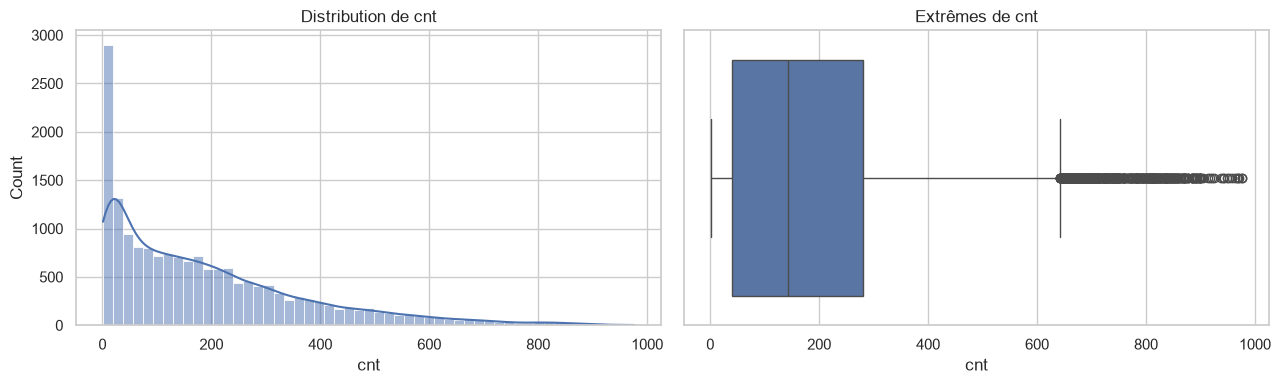

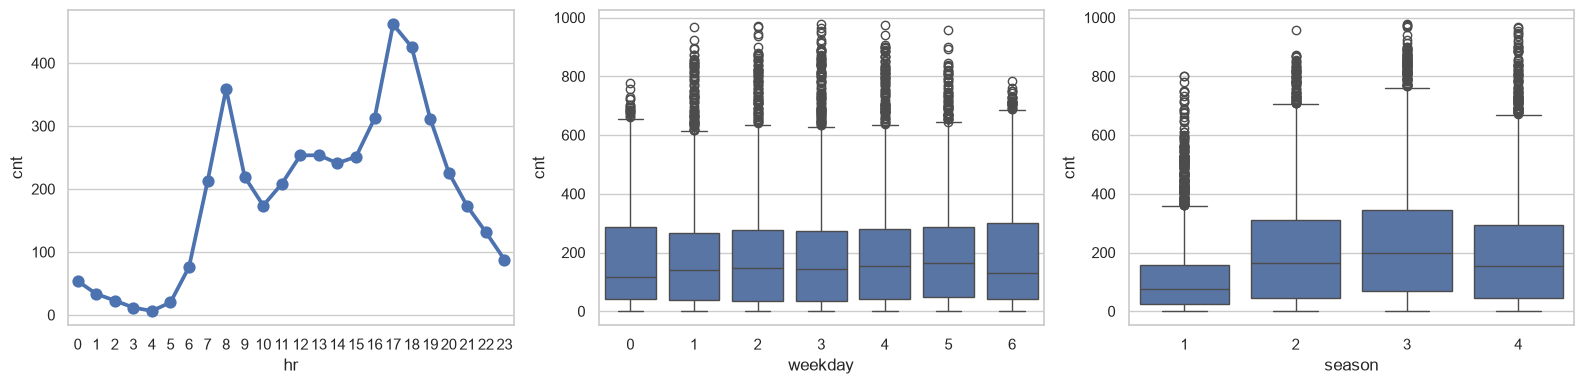

In [5]:
fig, ax = plt.subplots(1,2,figsize=(13,4))
sns.histplot(df.cnt,kde=True,ax=ax[0]); ax[0].set_title('Distribution de cnt')
sns.boxplot(x=df.cnt,ax=ax[1]); ax[1].set_title('Extrêmes de cnt')
plt.tight_layout()
if 'hr' in df:
    fig, ax = plt.subplots(1,3,figsize=(16,4))
    sns.pointplot(data=df,x='hr',y='cnt',errorbar=None,ax=ax[0])
    sns.boxplot(data=df,x='weekday',y='cnt',ax=ax[1])
    sns.boxplot(data=df,x='season',y='cnt',ax=ax[2])
    plt.tight_layout()
else:
    df.boxplot(column='cnt',by='season')

Conclusion distribution/temps : commenter asymétrie, extrêmes et groupes associés aux demandes différentes. Une association n'est pas une causalité.

## 6. Corrélations numériques
Pearson décrit les relations linéaires, et ne suffit pas pour interpréter les variables codées catégorielles.

,corrélation avec cnt
registered,0.972151
casual,0.694564
temp,0.404772
atemp,0.400929
hr,0.394071
hum,-0.322911
instant,0.278379
yr,0.250495
year_calendar,0.250495
season,0.178056


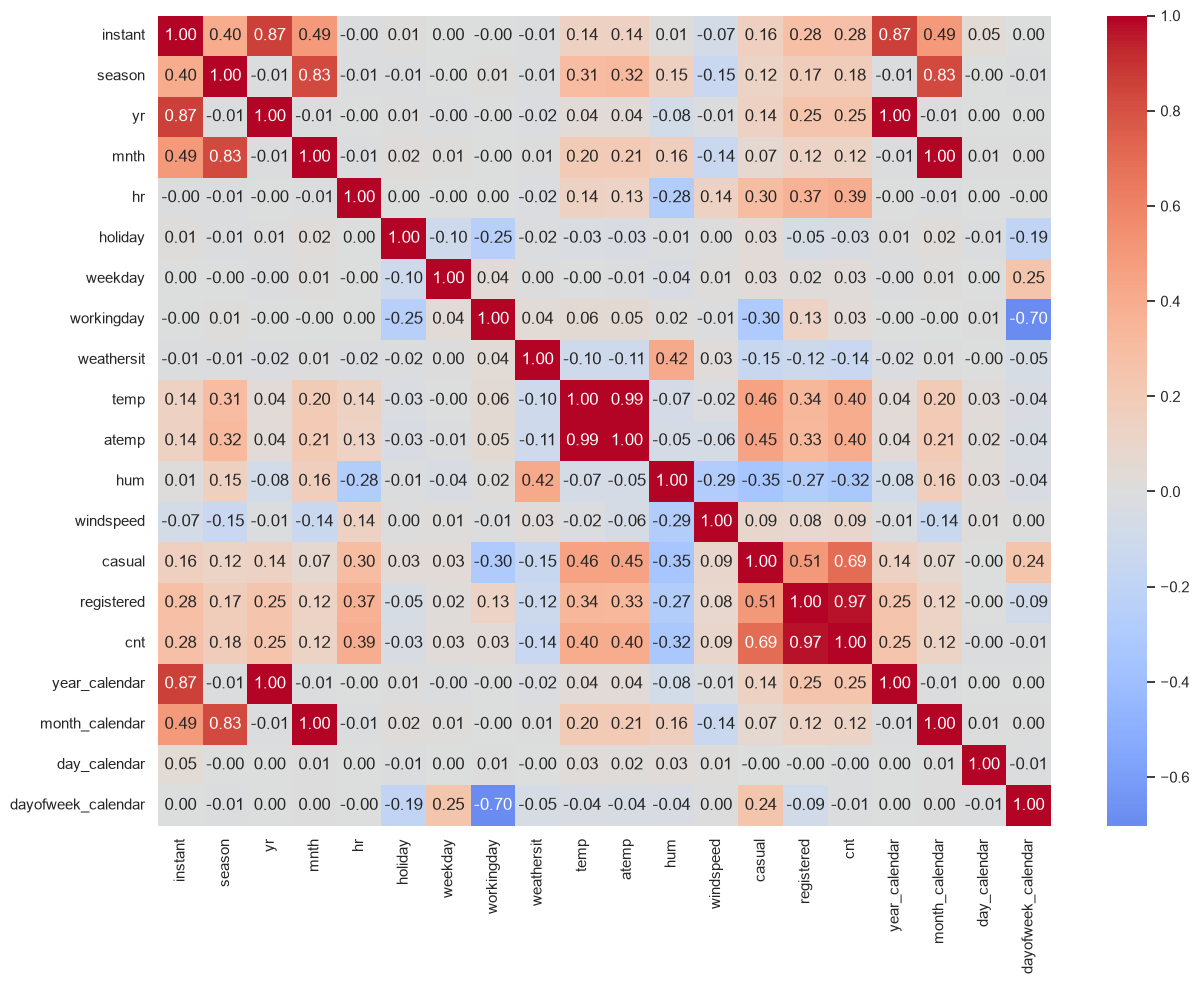

In [6]:
corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(13,10)); sns.heatmap(corr,cmap='coolwarm',center=0,annot=True,fmt='.2f'); plt.tight_layout()
display(corr.cnt.drop('cnt').sort_values(key=lambda s:s.abs(),ascending=False).to_frame('corrélation avec cnt'))

Conclusion corrélations : relever les variables associées à cnt et les prédicteurs corrélés, dont temp/atemp. La corrélation seule ne justifie pas une suppression; Ridge aide avec la colinéarité.

## 7. Comparaison des variables catégorielles

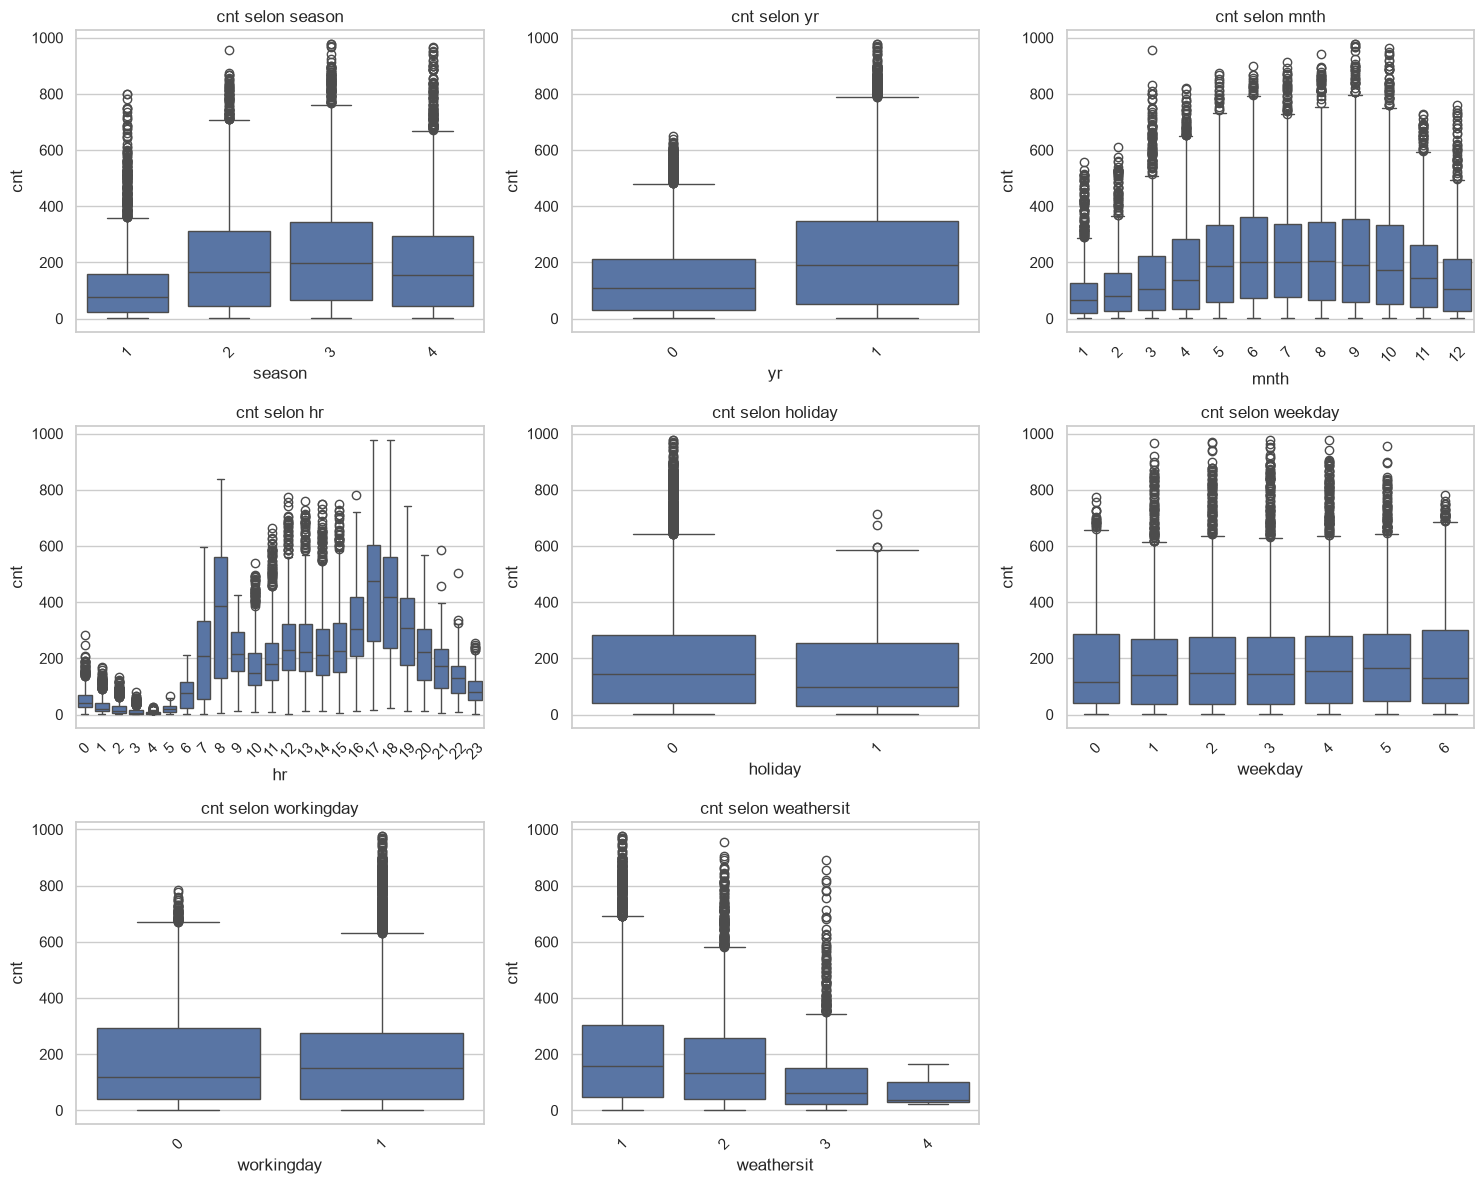

In [7]:
cats=[c for c in ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit'] if c in df]
rows=int(np.ceil(len(cats)/3)); fig, axes=plt.subplots(rows,3,figsize=(15,4*rows)); axes=np.array(axes).reshape(-1)
for ax,c in zip(axes,cats): sns.boxplot(data=df,x=c,y='cnt',ax=ax); ax.set_title(f'cnt selon {c}'); ax.tick_params(axis='x',rotation=45)
for ax in axes[len(cats):]: ax.remove()
plt.tight_layout()

Conclusion catégorielles : noter les catégories où cnt change; encoder en one-hot pour les modèles linéaires.

## 8. Décisions provisoires
- Exclure casual, registered (fuite), instant (index), dteday brute (date transformée).
- Garder provisoirement météo, calendrier, heure.
- Évaluer les redondances temp/atemp, saison/mois, weekday/holiday/workingday. Confirmer toute élimination par validation des modèles.

## 9. Prétraitement pour la comparaison
Découpage chronologique pour tester sur les périodes futures. Imputation, encodage et standardisation seront intégrés aux pipelines.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
excluded={TARGET,'casual','registered','instant','dteday'}
feature_cols=[c for c in df.columns if c not in excluded]
X,y=df[feature_cols].copy(),df[TARGET].copy()
categorical_features=[c for c in ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit','month_calendar','dayofweek_calendar'] if c in X]
numeric_features=[c for c in X if c not in categorical_features]
order=np.argsort(df.dteday.to_numpy(),kind='stable'); n=len(order); a,b=int(.70*n),int(.85*n)
idx_train,idx_valid,idx_test=order[:a],order[a:b],order[b:]
X_train,y_train=X.iloc[idx_train],y.iloc[idx_train]; X_valid,y_valid=X.iloc[idx_valid],y.iloc[idx_valid]; X_test,y_test=X.iloc[idx_test],y.iloc[idx_test]
numeric_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
category_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
preprocessor=ColumnTransformer([('num',numeric_pipe,numeric_features),('cat',category_pipe,categorical_features)])
print('Train/validation/test:',len(idx_train),len(idx_valid),len(idx_test)); print(feature_cols)

Train/validation/test: 12165 2607 2607
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year_calendar', 'month_calendar', 'day_calendar', 'dayofweek_calendar']


## 10. Conclusion générale
À compléter après exécution : variables associées à cnt, variables redondantes et choix validés. Le test final ne doit servir qu'une fois. Cette première version couvre exploration et préparation; la comparaison chiffrée des cinq modèles sera ajoutée ensuite.